# Identificando número de K do k-means - SSE 

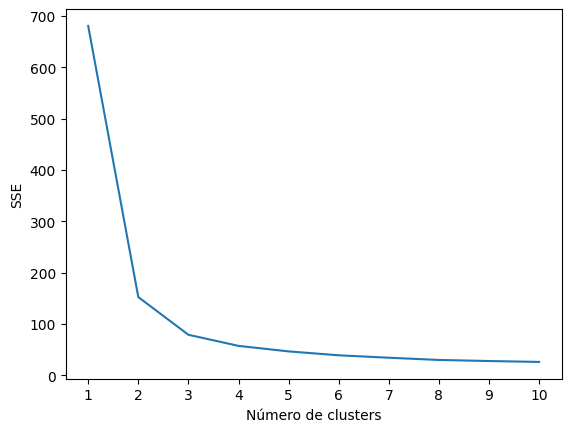

In [2]:
import pandas as pd
from sklearn.cluster import KMeans
from matplotlib import pyplot as plt

dfIris = pd.read_csv('Iris.csv').set_index('Id')
X = dfIris.iloc[:,0:4]

sse = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, n_init=50)
    kmeans.fit(X)
    # O parâmetro "inertia_" representa a soma dos quadrados das distâncias das amostras ao centro do cluster mais próximo.
    sse.append(kmeans.inertia_)
    
    
plt.plot(range(1, 11), sse)
plt.xticks(range(1, 11))
plt.xlabel("Número de clusters")
plt.ylabel("SSE")
plt.show()

### Observação

###### Aqui temos a indicação de que 3 é um bom número de clusters. Veja o "cotovelo" da curva.

# Identificando número de K do k-means - Calinski Harabsz 

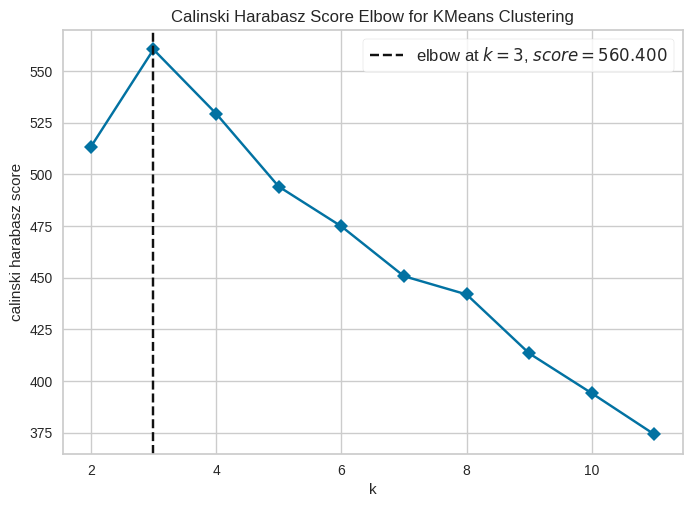

<AxesSubplot:title={'center':'Calinski Harabasz Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='calinski harabasz score'>

In [3]:
from yellowbrick.cluster import KElbowVisualizer

dfIris = pd.read_csv('Iris.csv').set_index('Id')
X = dfIris.iloc[:,0:4]

# Inicializa o modelo e o visualizador (usando a YellowBrick)
model = KMeans(n_init=50)
visualizer = KElbowVisualizer(
    model, k=(2,12), metric='calinski_harabasz', timings=False
)

visualizer.fit(X)        
visualizer.show()        

Obs: calinski harabasz é também conhecida como Variance Ratio Criterion.

calinski_harabasz = disperção dentro do cluster / disperção entre clusters

# Identificando número de K do k-means - Silhueta da distribuição

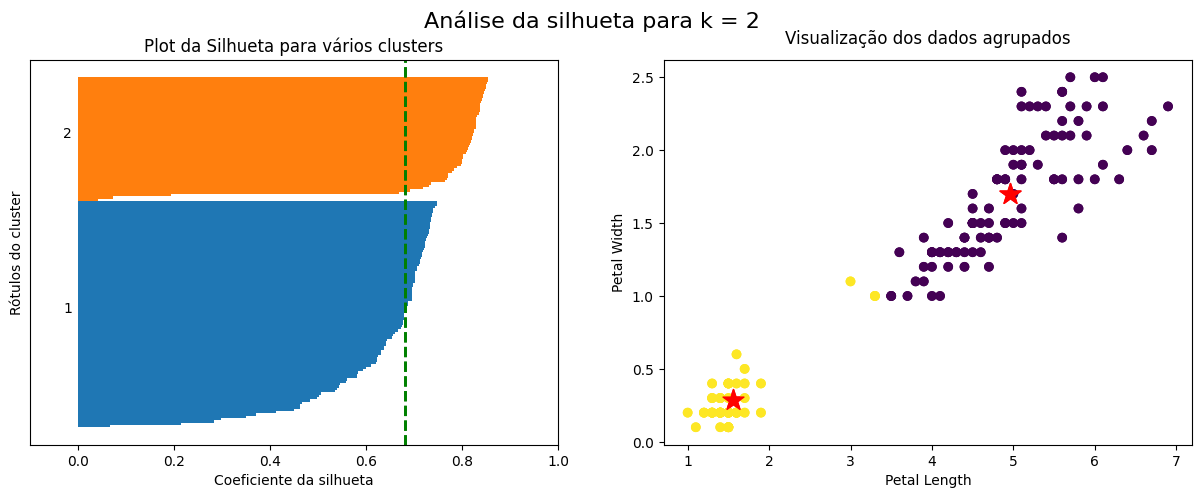

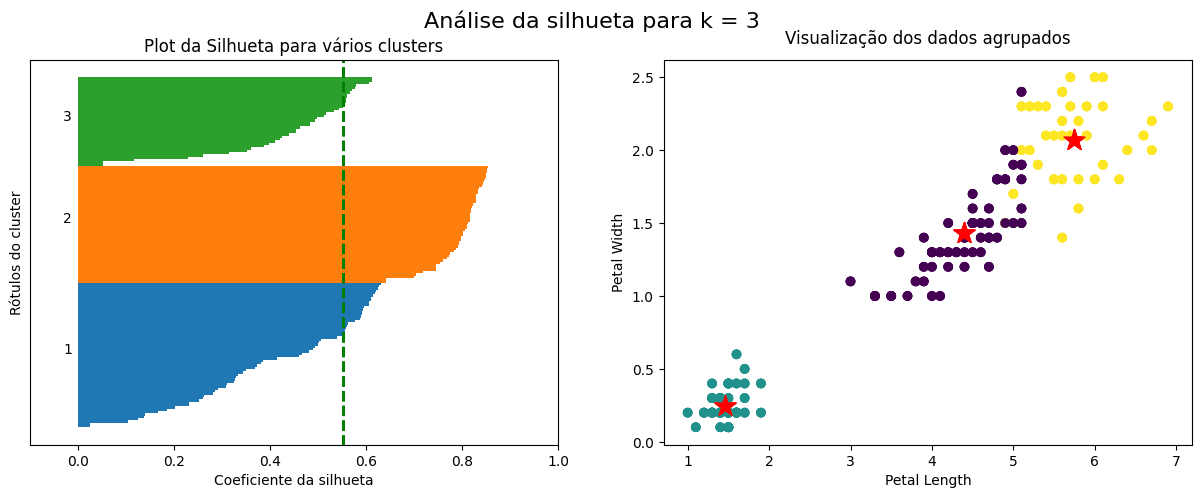

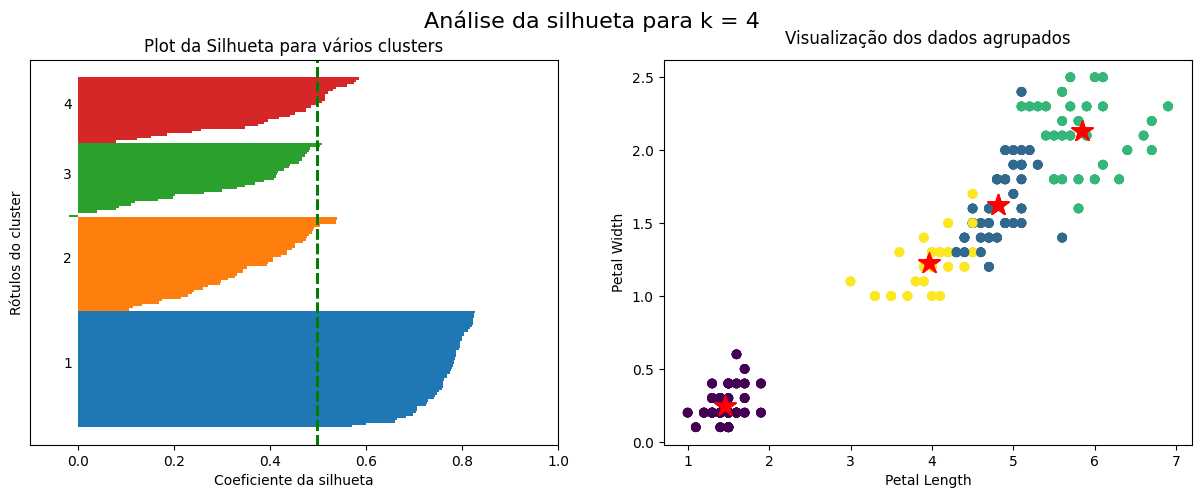

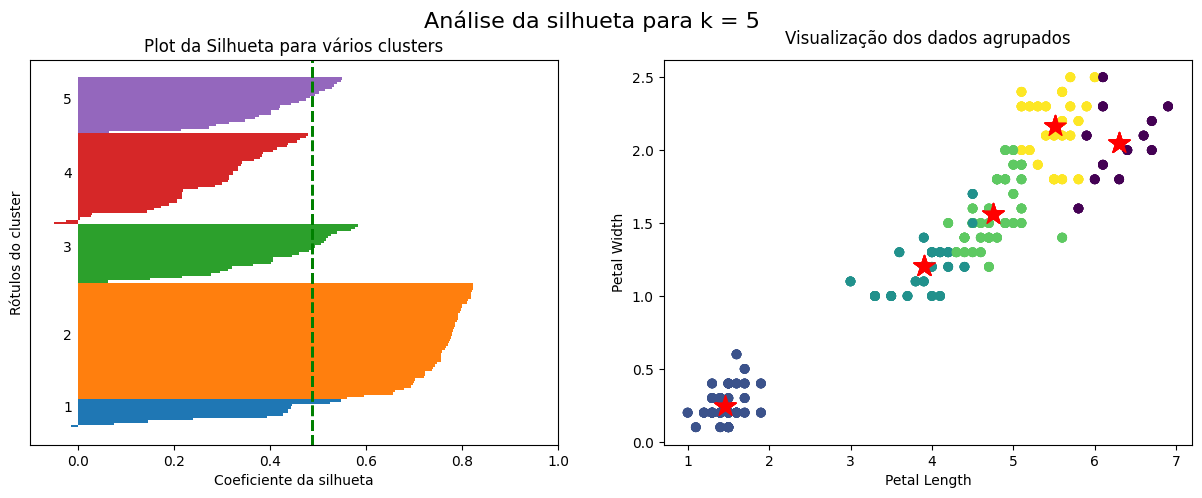

In [3]:
# Implementações para o cálculo da silhueta média e individual
from sklearn.metrics import silhouette_samples,silhouette_score
from sklearn.cluster import KMeans
import numpy as np

dfIris = pd.read_csv('Iris.csv').set_index('Id')
X = dfIris.iloc[:,0:4]

# Calcular o coeficiente da silhueta 
for i,k in enumerate([2,3,4,5]):
    
    fig, ax = plt.subplots(1,2,figsize=(15,5))
    
    # k-Means
    km = KMeans(n_clusters=k, n_init=50, random_state=42)
    y_predict = km.fit_predict(X)
    centroids  = km.cluster_centers_
    

    # Silhueta
    silhouette_vals = silhouette_samples(X,y_predict)
    
    # Plot da Silhueta
    y_ticks = []
    y_lower = y_upper = 0
    
    for i,cluster in enumerate(np.unique(y_predict)):
        cluster_silhouette_vals = silhouette_vals[y_predict == cluster]
        cluster_silhouette_vals.sort()
        y_upper += len(cluster_silhouette_vals)

        ax[0].barh(range(y_lower,y_upper),
        cluster_silhouette_vals,height =1);
        ax[0].text(-0.03,(y_lower+y_upper)/2,str(i+1))
        y_lower += len(cluster_silhouette_vals)

        # Pega o coeficiente silhueta média (de todos os pontos) 
        avg_score = np.mean(silhouette_vals)
        ax[0].axvline(avg_score,linestyle ='--', linewidth =2,color = 'green')
        ax[0].set_yticks([])
        ax[0].set_xlim([-0.1, 1])
        ax[0].set_xlabel('Coeficiente da silhueta')
        ax[0].set_ylabel('Rótulos do cluster')
        ax[0].set_title('Plot da Silhueta para vários clusters');

        # scatter plot dos dados coloridos pelos labels 
        ax[1].scatter(X['PetalLengthCm'],X['PetalWidthCm'] , c = y_predict);
        ax[1].scatter(centroids[:,2],centroids[:,3],marker = '*' , c= 'r',s =250);
        ax[1].set_xlabel('Petal Length')
        ax[1].set_ylabel('Petal Width')
        ax[1].set_title('Visualização dos dados agrupados', y=1.02)

        plt.suptitle('Análise da silhueta para k = '+str(k),fontsize=16)

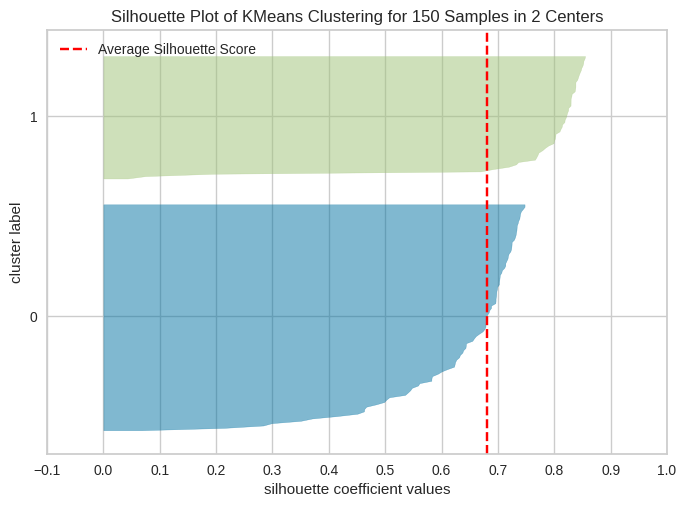

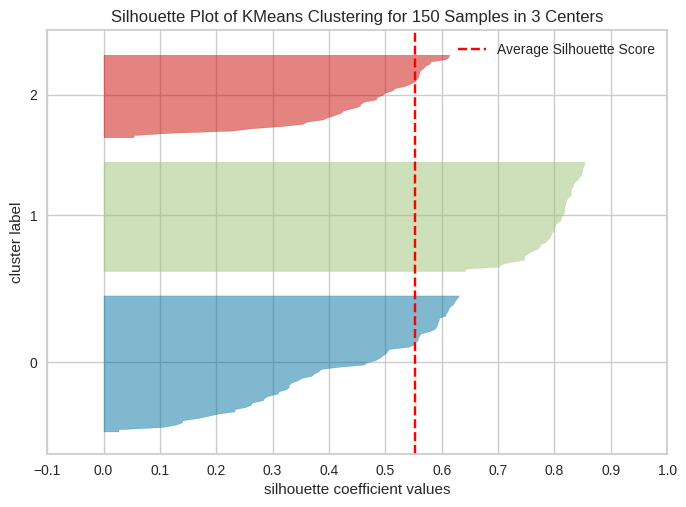

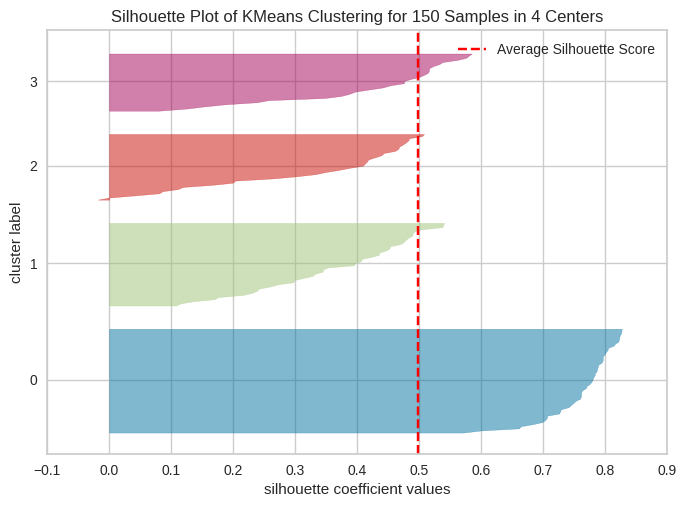

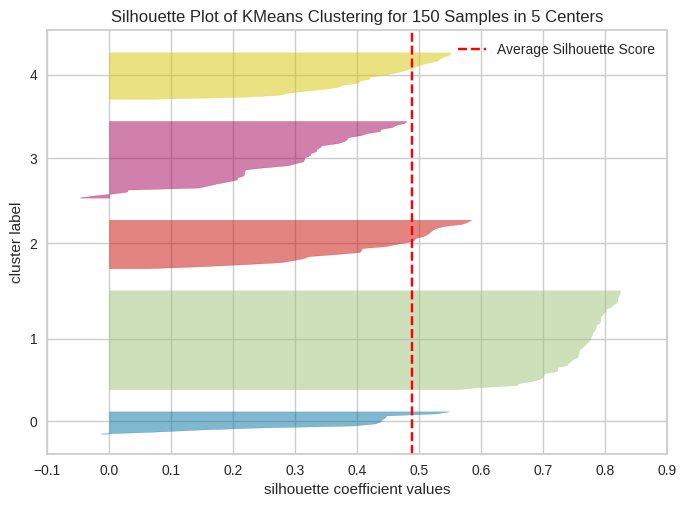

In [5]:
from yellowbrick.cluster import SilhouetteVisualizer

dfIris = pd.read_csv('Iris.csv').set_index('Id')
X = dfIris.iloc[:,0:4]

for k in range(2,6):

    # Inicializa o modelo e o visualizador (usando a YellowBrick)
    model = KMeans(k, random_state=42, n_init=50)
    visualizer = SilhouetteVisualizer(model, colors='yellowbrick')

    visualizer.fit(X)        # Ajusta os dados ao visualizador
    visualizer.show()        # Mostra a figura

### Observações

##### A grossura do plot da silhueta representa o tamanho do grupo.
##### Queremos clusters acima da média de silhueta (linha pontilhada). Assim, 4 e 5 não são interessantes. 

# Identificando EPS e minpts (DBSCAN)

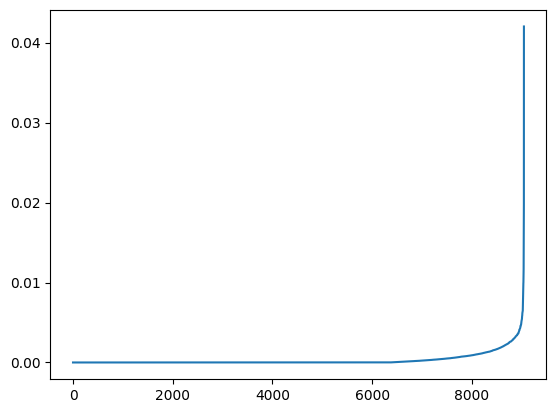

In [5]:
from sklearn.neighbors import NearestNeighbors
from matplotlib import pyplot as plt

dfCheckinBH = pd.read_csv('BHcheckins.txt', sep='\t', header=None)

neighbors = NearestNeighbors(n_neighbors=4)
neighbors_fit = neighbors.fit(dfCheckinBH)


distances, indices = neighbors_fit.kneighbors(dfCheckinBH)


distances = np.sort(distances, axis=0)
distances = distances[:,1]

plt.plot(distances)

### Visualizando o resultado

In [7]:
#Para visualizar em mapas
import folium
from folium.plugins import HeatMap
from sklearn.cluster import DBSCAN

mapaBH = folium.Map(location=[-19.925684, -43.938196])

kms_por_radian = 6371.0088
#0.1 = 100 metros
epsilon = 0.005 / kms_por_radian #convertendo para radiano, scikit-learn trabalha com essa unidade

#demanda converter as coordenadas para radianos
db = DBSCAN(eps=epsilon, min_samples=40, metric='haversine').fit (np.radians(dfCheckinBH))

dfCheckinBH_filtered = dfCheckinBH[db.labels_ !=-1]

print(len(dfCheckinBH))
print(len(dfCheckinBH_filtered))

pontos  = [[row[0],row[1]] for index, row in dfCheckinBH_filtered.iterrows()]

db = DBSCAN(eps=epsilon, min_samples=40, metric='haversine').fit_predict(np.radians(dfCheckinBH))

#Imprime os clusters e os elementos associados a eles. -1 são ruídos. 
print(np.unique(db, return_counts=True))
HeatMap(pontos).add_to(mapaBH)
mapaBH



9043
6100
(array([-1,  0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15,
       16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32,
       33, 34, 35]), array([2943,   51, 3161,   71,  190,  130,   75,   88,   49,  150,   41,
         71,   88,  207,   43,  106,  172,   62,   69,  173,   69,  105,
        125,   63,  124,   63,   53,   58,   81,   42,   55,   37,   41,
         38,   65,   44,   40]))


# Cophenetic correlation coeficient (clusterização hierárquica)

In [8]:
from scipy.cluster.hierarchy import complete, ward, cophenet
from scipy.spatial.distance import pdist, squareform

### Complete + euclidean

In [9]:
dfIris = pd.read_csv('Iris.csv').set_index('Id')
X = dfIris.iloc[:,0:4]


distOriginal = pdist(X,metric="euclidean")

Z = complete(pdist(X,metric="euclidean"))
Cophe = cophenet(Z)

#Correlação
np.corrcoef(distOriginal, Cophe)[0,1]

0.7271703099916064

### Ward + euclidean

In [10]:
distOriginal = pdist(X,metric="euclidean")

Z = ward(pdist(X,metric="euclidean"))
Cophe = cophenet(Z)

#Correlação
np.corrcoef(distOriginal, Cophe)[0,1]

0.8726015250644709

# Fuzzy c-means

In [15]:
#!pip install fuzzy-c-means

import numpy as np
from fcmeans import FCM
from matplotlib import pyplot as plt
import pandas as pd

In [14]:
dfIris = pd.read_csv('Iris.csv').set_index('Id')

fcm = FCM(n_clusters=3, m=2)

#Pacote demnda o formato NumPy array
X = dfIris.iloc[:,0:4].to_numpy()
fcm.fit(X)

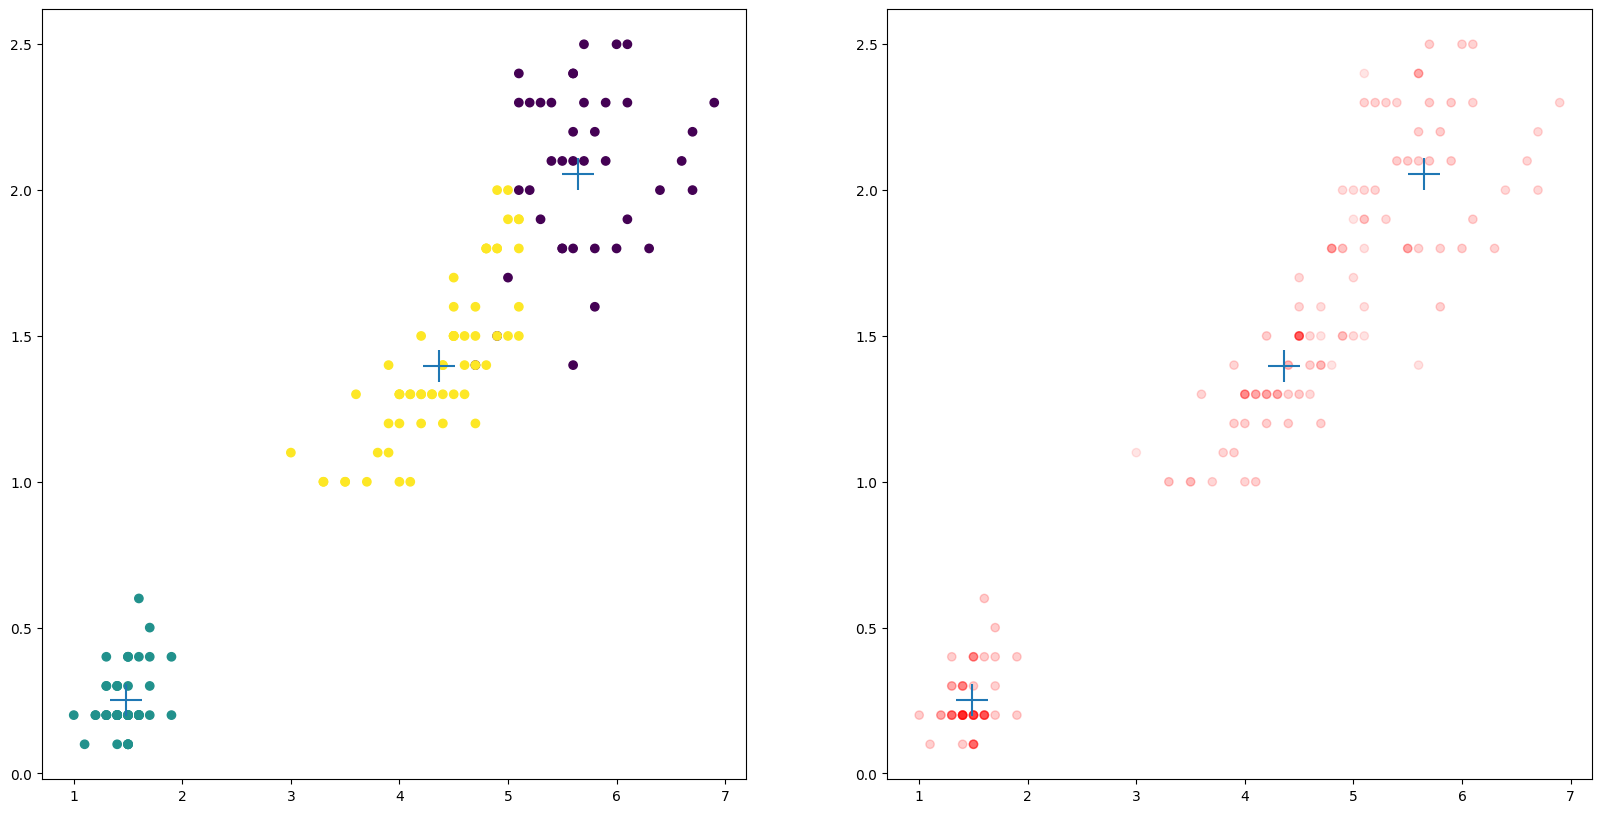

In [18]:
# saídas
fcm_centers = fcm.centers
fcm_labels = fcm.predict(X)

# plot para os resulados
f, axes = plt.subplots(1, 2, figsize=(20,10))

#fcm.u contém o grau de pertencimento de um objeto a um cluster
#Estou dividindo por 5 só para o valor do grau de transparente ficar mais destacado na figura
listAphas = (np.amax(fcm.u, keepdims=False, axis=1)/5).tolist()

axes[0].scatter(X[:,2], X[:,3], c=fcm_labels)

axes[0].scatter(fcm_centers[:,2], fcm_centers[:,3], marker="+", s=500)

### plot com alpha de acordo com a maior probabilidade de pertencimento ao cluster ##
rgba_colors = np.zeros((len(listAphas),4))

# Cor vermelha
rgba_colors[:,0] = 1.0
# Alpha de acordo com as probabilidades
rgba_colors[:, 3] = listAphas

axes[1].scatter(X[:,2], X[:,3], color=rgba_colors)
axes[1].scatter(fcm_centers[:,2], fcm_centers[:,3], marker="+", s=500)

plt.show()

In [47]:
print(fcm.u)
print(fcm_labels)


[[9.96336000e-01 1.16345064e-03 2.50054979e-03]
 [9.76957452e-01 7.15564297e-03 1.58869049e-02]
 [9.80312281e-01 6.26056153e-03 1.34271579e-02]
 [9.68317232e-01 9.83250129e-03 2.18502670e-02]
 [9.93927318e-01 1.94172667e-03 4.13095559e-03]
 [9.33150762e-01 2.10698741e-02 4.57793639e-02]
 [9.79490247e-01 6.50561032e-03 1.40041423e-02]
 [9.99610776e-01 1.21407620e-04 2.67816422e-04]
 [9.31566491e-01 2.15314579e-02 4.69020506e-02]
 [9.83692974e-01 5.04220818e-03 1.12648177e-02]
 [9.67218255e-01 1.04648252e-02 2.23169200e-02]
 [9.92281789e-01 2.38658934e-03 5.33162207e-03]
 [9.71751271e-01 8.83081112e-03 1.94179175e-02]
 [9.23706664e-01 2.49970067e-02 5.12963289e-02]
 [8.88407528e-01 3.80950700e-02 7.34974018e-02]
 [8.39287635e-01 5.50126411e-02 1.05699724e-01]
 [9.45522606e-01 1.79592184e-02 3.65181752e-02]
 [9.96307534e-01 1.16808547e-03 2.52438081e-03]
 [9.03074943e-01 3.06454352e-02 6.62796215e-02]
 [9.78070537e-01 7.01183183e-03 1.49176313e-02]
 [9.68760168e-01 9.49389377e-03 2.174593